In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

tips = pd.read_csv("tips.csv")

X = tips[["total_bill"]]
y = tips["tip"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 170
Testing rows: 74


I seperated the data into both training and testing groups because I wanted to see how well the model works on information it hasn't seen before. If we were to test it on the same data it learned from, the results could be positively skewed.

In [3]:
reg_model = LinearRegression()
reg_model.fit(X_train, y_train)

slope = reg_model.coef_[0]
intercept = reg_model.intercept_

print("Slope:", slope)
print("Intercept:", intercept)
print(f"Each extra dollar of the bill adds about ${slope:.2f} to the predicted tip.")

Slope: 0.10889370921420226
Intercept: 0.8769576391532707
Each extra dollar of the bill adds about $0.11 to the predicted tip.


So based on the regression results, I found that every additional dollar on the restaurant bill was associated with about 11 cents more in the predicted tip.

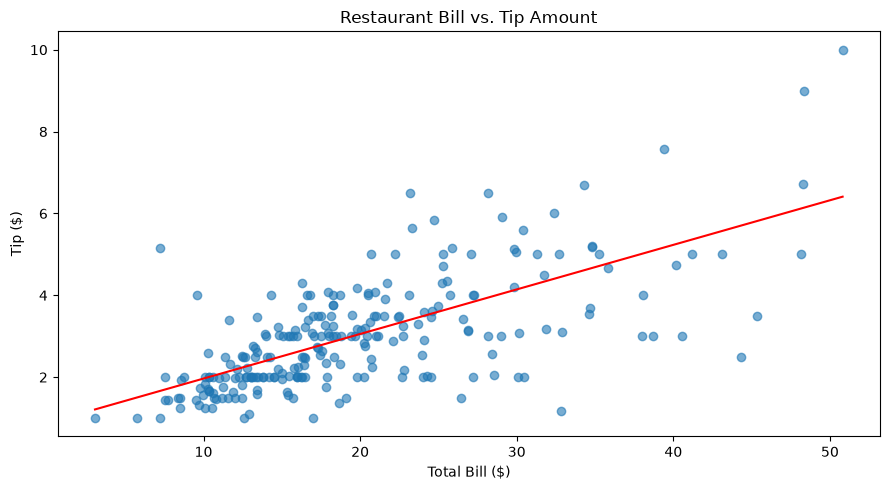

In [4]:
plt.figure(figsize=(9, 5))

plt.scatter(tips["total_bill"], tips["tip"], alpha=0.6)

x_line = np.linspace(
    tips["total_bill"].min(),
    tips["total_bill"].max(),
    100
)

y_line = reg_model.predict(
    pd.DataFrame({"total_bill": x_line})
)

plt.plot(x_line, y_line, color="red")

plt.title("Restaurant Bill vs. Tip Amount")
plt.xlabel("Total Bill ($)")
plt.ylabel("Tip ($)")

plt.tight_layout()
plt.show()

In [5]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)

X_iris = iris.data
y_iris = iris.target

Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    X_iris, y_iris, test_size=0.3, random_state=42
)

print("Total flowers:", len(X_iris))
print("Training flowers:", len(Xi_train))
print("Testing flowers:", len(Xi_test))

Total flowers: 150
Training flowers: 105
Testing flowers: 45


In [6]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(Xi_train, yi_train)

knn_test_score = knn.score(Xi_test, yi_test)

print("kNN test accuracy:", knn_test_score)

kNN test accuracy: 1.0


Decision tree test accuracy: 1.0


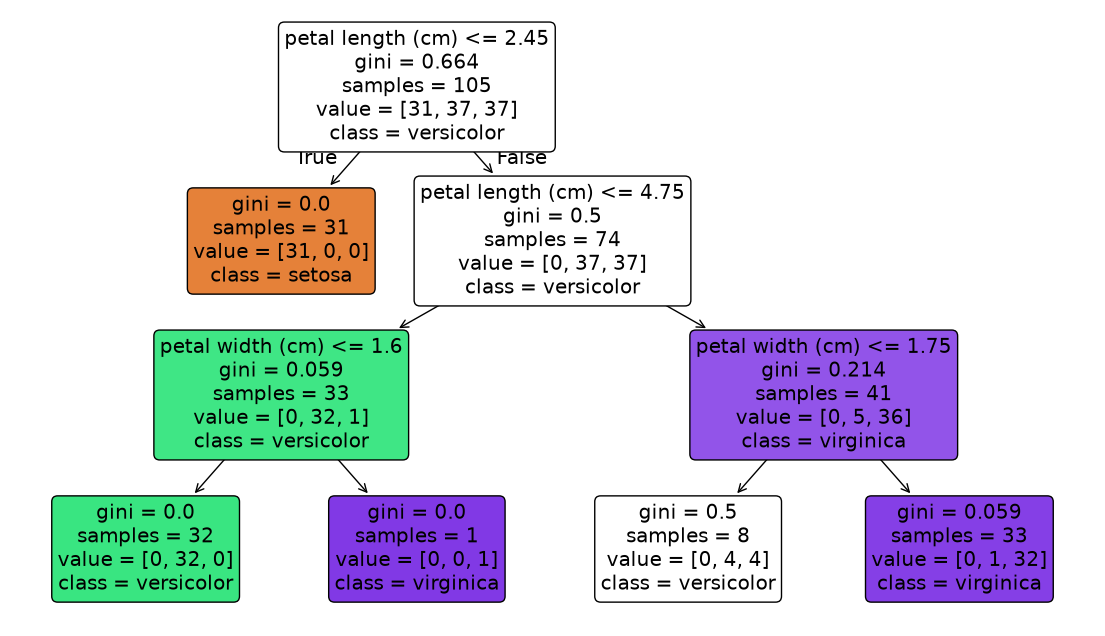

In [7]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(Xi_train, yi_train)

tree_test_score = tree.score(Xi_test, yi_test)

print("Decision tree test accuracy:", tree_test_score)

plt.figure(figsize=(14, 8))

plot_tree(
    tree,
    feature_names=X_iris.columns,
    class_names=iris.target_names,
    filled=True,
    rounded=True
)

plt.show()

In [8]:
deep_tree = DecisionTreeClassifier(random_state=42)
deep_tree.fit(Xi_train, yi_train)

comparison = pd.DataFrame({
    "Model": ["Shallow Tree", "Unlimited Tree"],
    "Training Accuracy": [
        tree.score(Xi_train, yi_train),
        deep_tree.score(Xi_train, yi_train)
    ],
    "Testing Accuracy": [
        tree.score(Xi_test, yi_test),
        deep_tree.score(Xi_test, yi_test)
    ]
})

comparison

,Model,Training Accuracy,Testing Accuracy
0,Shallow Tree,0.952381,1.0
1,Unlimited Tree,1.000000,1.0


What I noticed most was that the unlimited tree had the higher percentage of the two at 100%, compared to the shallow tree's 95.24%. What was interesting though was the fact that both models got 100% on the testing data, so the unlimited tree's didnt have a better peformance on the newer data.

In [9]:
new_flower = pd.DataFrame(
    [[5.5, 2.8, 4.2, 1.3]],
    columns=X_iris.columns
)

prediction = knn.predict(new_flower)[0]

print("Predicted species:", iris.target_names[prediction])

Predicted species: versicolor


For this assignment, I used linear regression to see if the total restaurant bill had anything to do with how much someone would tip. I also tested two different models, kNN and a decision tree, to see how well they could predict different flower species. However, the thing I found the most interesting was the fact that that both models actually got 100% accuracy on the testing data. So this being said, if I were to choose one, would probably pick kNN as it had similar levels of performance with the benefit of being straightforward. 
One concern I would have though is if the model would still perform as well on flowers with measurements that are different from the ones it was trained on. So with this, if this was being used to make predictions about people instead, I'd also be worried about certain groups being underrepresented in the training data, which could lead to unfair results.

GitHub Repository

https://github.com/leonhong2007/cs82a-portfolio/tree/main/module7